In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import VotingClassifier, RandomForestClassifier, BaggingClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, accuracy_score

# Load data
df = pd.read_csv("/content/drive/MyDrive/My work/Air Quality Project/Paper 1(External Data)/New/DS2_aqi_corrected_cleaned.csv")

# Encode labels
label_enc = LabelEncoder()
df['AQI_Label'] = label_enc.fit_transform(df['AQI_Category'])

# Define features and target
features = ['SO2', 'NO2', 'CO', 'O3', 'PM2.5', 'PM10']
X = df[features]
y = df['AQI_Label']


In [3]:
# ============================================================
# STEP 1: Train-Test Split (Before Normalization)
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# ============================================================
# STEP 2: Normalize Features (Avoid Data Leakage)
# ============================================================

scaler = StandardScaler()

# Fit scaler only on training data
X_train = scaler.fit_transform(X_train)

# Transform test data using training scaler
X_test = scaler.transform(X_test)

# ============================================================
# STEP 3: Define Individual Models
# ============================================================

xgb_model = XGBClassifier(
    use_label_encoder=False,
        eval_metric='mlogloss',
        random_state=42,
)

bagging_model = BaggingClassifier(
    max_samples=0.8,
        max_features=0.8,
        random_state=42,
)

rf_model = RandomForestClassifier(
    max_depth=6,
        max_features=0.8,
        random_state=42,)

# svm_model = SVC(
#     probability=True,
#     random_state=42
# )

# ============================================================
# STEP 4: Create Voting Ensemble
# ============================================================

voting_clf = VotingClassifier(
    estimators=[
        ('xgb', xgb_model),
        ('bagging', bagging_model),
        ('rf', rf_model),
        # ('svm', svm_model)
    ],
    voting='soft'
)

# ============================================================
# STEP 5: Train Ensemble
# ============================================================

voting_clf.fit(X_train, y_train)

# ============================================================
# STEP 6: Predict
# ============================================================

y_pred = voting_clf.predict(X_test)

# ============================================================
# STEP 7: Evaluation
# ============================================================

print("=== Voting Ensemble Classification Report ===")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=label_enc.classes_,
        digits=4,
        zero_division=0
    )
)

print("Accuracy:", accuracy_score(y_test, y_pred))

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [17:50:58] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


=== Voting Ensemble Classification Report ===
              precision    recall  f1-score   support

        Good     0.9996    0.9996    0.9996      2353
    Moderate     0.9985    0.9996    0.9991      4770
        Poor     1.0000    0.9965    0.9982      2564
Satisfactory     0.9995    0.9995    0.9995      6246
      Severe     1.0000    0.9994    0.9997      1767
   Very Poor     0.9991    1.0000    0.9995      5485

    accuracy                         0.9993     23185
   macro avg     0.9995    0.9991    0.9993     23185
weighted avg     0.9993    0.9993    0.9993     23185

Accuracy: 0.999309898641363


In [4]:
# ============================================================
# STEP 8: MULTICLASS AVERAGE PRECISION (AP)
# ============================================================

import os
import numpy as np
import pandas as pd

from sklearn.metrics import average_precision_score
from sklearn.preprocessing import label_binarize

# ------------------------------------------------------------
# 1. Obtain predicted class probabilities
# ------------------------------------------------------------

y_proba = voting_clf.predict_proba(X_test)

# Use the exact class order of the trained voting classifier
classes = voting_clf.classes_

# ------------------------------------------------------------
# 2. Convert true labels to one-vs-rest format
# ------------------------------------------------------------

y_test_bin = label_binarize(
    y_test,
    classes=classes
)

# ------------------------------------------------------------
# 3. Calculate AP for each AQI category
# ------------------------------------------------------------

ap_results = []

for i, class_id in enumerate(classes):

    class_ap = average_precision_score(
        y_test_bin[:, i],
        y_proba[:, i]
    )

    class_name = label_enc.inverse_transform(
        [int(class_id)]
    )[0]

    ap_results.append({
        "AQI Category": class_name,
        "Support": int(y_test_bin[:, i].sum()),
        "Average Precision": class_ap
    })

ap_df = pd.DataFrame(ap_results)

# ------------------------------------------------------------
# 4. Calculate Macro, Weighted, and Micro AP
# ------------------------------------------------------------

macro_ap = average_precision_score(
    y_test_bin,
    y_proba,
    average="macro"
)

weighted_ap = average_precision_score(
    y_test_bin,
    y_proba,
    average="weighted"
)

micro_ap = average_precision_score(
    y_test_bin,
    y_proba,
    average="micro"
)

# ------------------------------------------------------------
# 5. Display results
# ------------------------------------------------------------

print("\n=== CLASS-WISE AVERAGE PRECISION ===")

print(
    ap_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

print("\n=== OVERALL AP RESULTS ===")
print(f"Macro AP    : {macro_ap:.6f}")
print(f"Weighted AP : {weighted_ap:.6f}")
print(f"Micro AP    : {micro_ap:.6f}")

# ------------------------------------------------------------
# 6. Save results to Google Drive
# ------------------------------------------------------------

output_dir = (
    "/content/drive/MyDrive/My work/Air Quality Project/"
    "Paper 1(External Data)/New"
)

os.makedirs(output_dir, exist_ok=True)

ap_df.to_csv(
    os.path.join(output_dir, "DS2_Voting_Ensemble_Classwise_AP.csv"),
    index=False
)

pd.DataFrame([{
    "Model": "Three-Model Soft-Voting Ensemble",
    "Macro_AP": macro_ap,
    "Weighted_AP": weighted_ap,
    "Micro_AP": micro_ap
}]).to_csv(
    os.path.join(output_dir, "DS2_Voting_Ensemble_Overall_AP.csv"),
    index=False
)

print(f"\nAP results saved successfully to:\n{output_dir}")


=== CLASS-WISE AVERAGE PRECISION ===
AQI Category  Support  Average Precision
        Good     2353           0.999999
    Moderate     4770           0.999969
        Poor     2564           0.999954
Satisfactory     6246           0.999999
      Severe     1767           0.999676
   Very Poor     5485           0.999938

=== OVERALL AP RESULTS ===
Macro AP    : 0.999923
Weighted AP : 0.999949
Micro AP    : 0.999929

AP results saved successfully to:
/content/drive/MyDrive/My work/Air Quality Project/Paper 1(External Data)/New


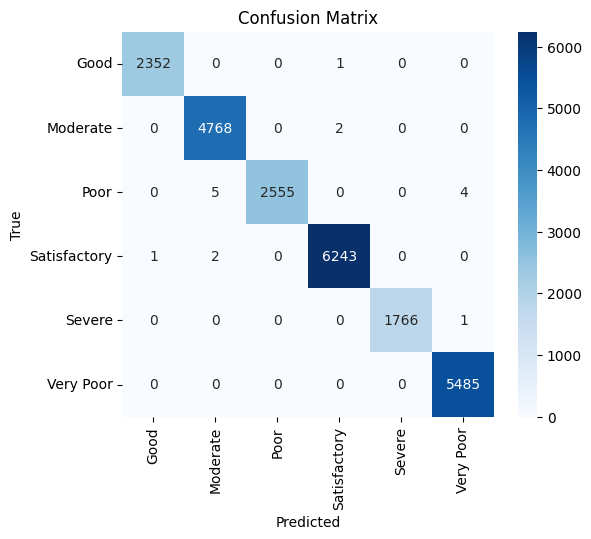

In [5]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import seaborn as sns # Import seaborn

# Assuming y_test (true labels) and y_pred (predicted labels) are available from previous steps
# Assuming label_enc (LabelEncoder) is available to get class names

# Compute the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Get the class names
class_names = label_enc.classes_
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d',
            xticklabels=label_enc.classes_, yticklabels=label_enc.classes_, # Corrected variable name from 'le' to 'label_enc'
            cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

In [7]:
# Count and print the occurrences of each unique location
location_counts = df['Location'].value_counts()
print("=== Location Counts ===")
print(location_counts)
print("\nTotal Unique Locations:", len(location_counts))
print("Total Records with Location Data:", location_counts.sum())

=== Location Counts ===
Location
Darussalam            18773
Sylhet                14746
BARC                  13482
Agrabad Chittagong    13071
Gazipur               11442
Narayonganj           11169
Barishal               9935
Rajshahi               9300
TV st-Chittagong       6248
Khulna                 3273
Sangsad                2350
Rangpur                1117
Mymansingh              592
Narsingdi               352
Savar                    57
Cumilla                  14
Name: count, dtype: int64

Total Unique Locations: 16
Total Records with Location Data: 115921


In [9]:
import pandas as pd

# Convert the 'Date' column to datetime (corrected case from 'date' to 'Date')
df['date_parsed'] = pd.to_datetime(df['Date'])

# Get the start and end dates
start_date = df['date_parsed'].min()
end_date = df['date_parsed'].max()

print(f"Start Date & Year: {start_date.strftime('%d-%m-%Y (%I:%M %p)')} (Year: {start_date.year})")
print(f"End Date & Year: {end_date.strftime('%d-%m-%Y (%I:%M %p)')} (Year: {end_date.year})")

Start Date & Year: 01-11-2012 (12:00 AM) (Year: 2012)
End Date & Year: 31-12-2020 (12:00 AM) (Year: 2020)


In [10]:
import sys
import pandas as pd
import sklearn
import xgboost as xgb
import numpy as np
import seaborn as sns
import matplotlib

print("=== Software & Library Versions ===")
print(f"Python       : {sys.version.split()[0]}")
print(f"pandas       : {pd.__version__}")
print(f"scikit-learn : {sklearn.__version__}")
print(f"xgboost      : {xgb.__version__}")
print(f"numpy        : {np.__version__}")
print(f"seaborn      : {sns.__version__}")
print(f"matplotlib   : {matplotlib.__version__}")

=== Software & Library Versions ===
Python       : 3.13.18
pandas       : 2.2.3
scikit-learn : 1.6.1
xgboost      : 3.4.1
numpy        : 2.4.6
seaborn      : 0.13.2
matplotlib   : 3.10.0
